# Конспект: pairplot, scatterplot, histplot, lineplot

## Правило выбора за 10 секунд

| Вопрос | График |
|---|---|
| Как связаны два числа? | scatterplot |
| Как распределено одно число? | histplot / histogram |
| Как меняется агрегированная величина в порядке? | lineplot |
| Как быстро посмотреть все пары числовых столбцов? | pairplot |

Перед графиком определите: что будет на X, что на Y, нужна ли группировка цветом и не надо ли сначала отсортировать/сгруппировать таблицу.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', palette='deep')

df = pd.read_csv('titanic.csv')
# Маленькая рабочая таблица: меньше столбцов — легче видеть смысл.
data = df[['survived', 'pclass', 'sex', 'age', 'fare', 'sibsp', 'parch']].copy()
data.head()

,survived,pclass,sex,age,fare,sibsp,parch
0,0,3,male,22.0,7.2500,1,0
1,1,1,female,38.0,71.2833,1,0
2,1,3,female,26.0,7.9250,0,0
3,1,1,female,35.0,53.1000,1,0
4,0,3,male,35.0,8.0500,0,0


## Нулевой шаблон: один чистый график

В олимпиадной задаче чаще всего достаточно такого каркаса:

    plt.figure(figsize=(7, 4))
    # один вызов графика
    plt.title('Что показываем')
    plt.xlabel('X'); plt.ylabel('Y')
    plt.show()

Подписи осей помогают и проверяющему, и вам: сразу видно, не перепутали ли вы количество, долю и исходные значения.

# 1. Scatterplot: две числовые переменные

Каждая точка — одна строка DataFrame. Scatter отвечает на вопрос: есть ли облако точек, тренд, кластеры, выбросы? Он не доказывает причинность.

Главная проблема — наложение точек. Почти всегда ставьте alpha от 0.2 до 0.7. Если столбец содержит пропуски, matplotlib и seaborn обычно не рисуют такие точки, но для контроля можно явно вызвать dropna.

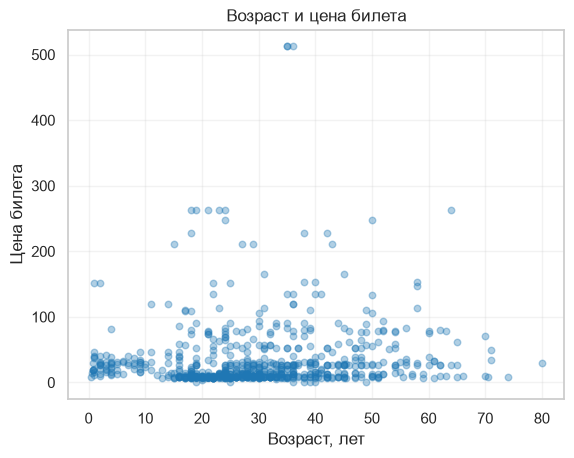

In [26]:
# matplotlib: самый прямой и быстрый вариант.
plot_data = data.dropna(subset=['age', 'fare'])
plt.scatter(plot_data['age'], plot_data['fare'], alpha=.35, s=22, color='tab:blue')


# оформление
plt.title('Возраст и цена билета')
plt.xlabel('Возраст, лет'); plt.ylabel('Цена билета')
plt.grid(alpha=.25)
plt.show()

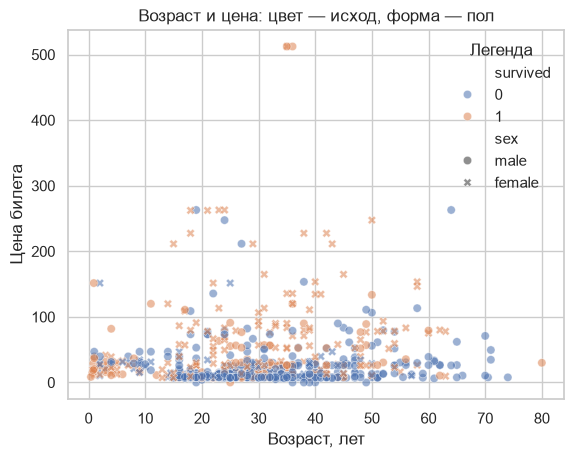

In [27]:
# seaborn: data= позволяет указывать имена столбцов строками.
sns.scatterplot(data=data, x='age', y='fare', hue='survived', style='sex', alpha=.55)


# оформление
plt.title('Возраст и цена: цвет — исход, форма — пол')
plt.xlabel('Возраст, лет'); plt.ylabel('Цена билета')
plt.legend(title='Легенда')
plt.show()

### Scatterplot: ключи, которые стоит знать

| Ключ | Где | Зачем |
|---|---|---|
| alpha=.4 | matplotlib и seaborn | прозрачность точек; видно плотность |
| s=20 | matplotlib | размер точки |
| c=... | matplotlib | цвет точек; для категорий лучше заранее сделать map |
| hue='sex' | seaborn | цвет показывает категорию |
| style='sex' | seaborn | форма маркера показывает категорию |
| size='fare' | seaborn | размер точки показывает число; используйте редко |
| plt.yscale('log') | matplotlib | сжать длинный хвост положительных чисел |

Олимпиадный вывод: если одна точка с огромным Y растягивает график, попробуйте log-шкалу или отдельно сообщите о выбросе.

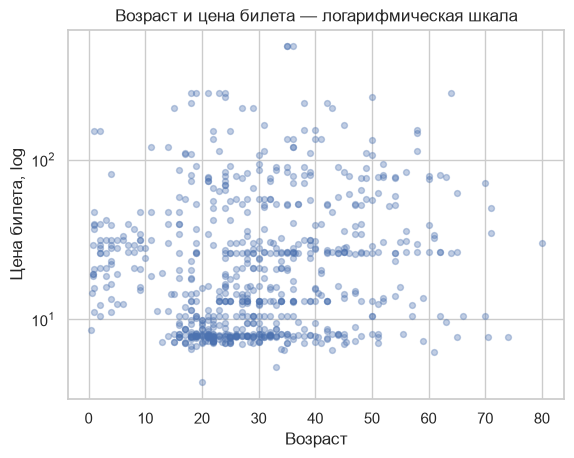

In [28]:
# Отдельный чистый график с log-шкалой: обычный уже был выше.
plt.scatter(plot_data['age'], plot_data['fare'], alpha=.35, s=18)

# оформление
plt.yscale('log')
plt.title('Возраст и цена билета — логарифмическая шкала')
plt.xlabel('Возраст'); plt.ylabel('Цена билета, log')
plt.show()

# 2. Histplot / histogram: распределение одного числа

Гистограмма делит числовую ось на интервалы bins и считает объекты в каждом. Она отвечает на вопрос: где сосредоточены значения, есть ли несколько пиков, длинный хвост, выбросы?

Bins меняют картинку. Не подбирайте число корзинок так, чтобы «доказать» желаемый вывод: попробуйте несколько разумных значений. Для олимпиады обычно хватает 15–30.

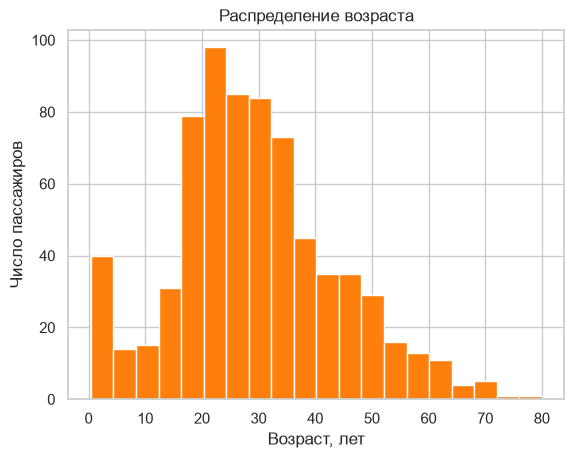

In [29]:
# matplotlib: count по умолчанию — число объектов в корзинке.
plt.hist(data['age'].dropna(), bins=20, color='tab:orange', edgecolor='white')


# оформление
plt.title('Распределение возраста')
plt.xlabel('Возраст, лет'); plt.ylabel('Число пассажиров')
plt.show()

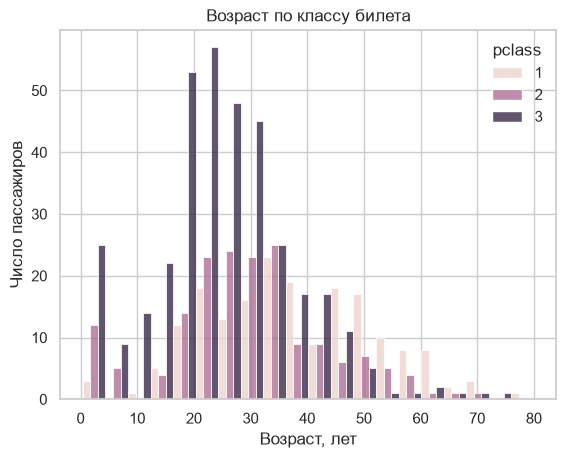

In [30]:
# seaborn: можно сразу разделить распределения по категориям.
sns.histplot(data=data, x='age', hue='pclass', bins=20, multiple='dodge')


# оформление
plt.title('Возраст по классу билета')
plt.xlabel('Возраст, лет'); plt.ylabel('Число пассажиров')
plt.show()

### Histplot: минимум ключей

| Ключ | Эффект |
|---|---|
| bins=20 | число корзинок |
| binwidth=5 | ширина корзинки; альтернативна bins |
| hue='pclass' | отдельные распределения по группам |
| multiple='layer' | группы накладываются с прозрачностью |
| multiple='stack' | группы складываются |
| multiple='dodge' | группы отображаются рядом друг с другом|
| stat='count' | высота = число объектов; значение по умолчанию |
| stat='density' | площадь гистограммы = 1; удобно сравнивать группы разного размера |
| kde=True | добавить сглаженную кривую; не путать с реальными данными |
| edgecolor='white' | границы столбиков в matplotlib |

Не используйте lineplot вместо гистограммы для несортированных исходных чисел: линия создаёт несуществующий порядок.

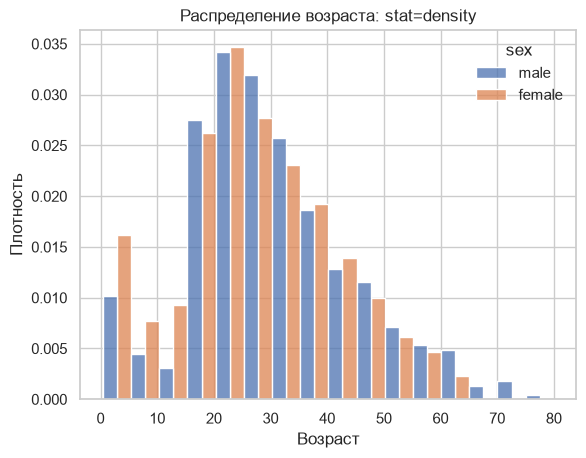

In [31]:
# Density полезнее count, когда сравниваем группы разного размера.
sns.histplot(data=data, x='age', hue='sex', bins=16, stat='density', common_norm=False, multiple='dodge')

# оформление
plt.title('Распределение возраста: stat=density')
plt.xlabel('Возраст'); plt.ylabel('Плотность')
plt.show()

# 3. Lineplot: сначала порядок или агрегация

Линия означает, что соседние X связаны порядком: время, номер, возрастная группа, размер массива. Нельзя соединять lineplot строки DataFrame в том порядке, в котором они лежат в файле.

Олимпиадный шаблон: groupby → agg/mean → sort_index/sort_values → plot. Ниже средняя доля выживших считается для каждого числа родственников на борту.

       доля выживших  пассажиров
sibsp                           
0           0.345395         608
1           0.535885         209
2           0.464286          28
3           0.250000          16
4           0.166667          18
5           0.000000           5
8           0.000000           7


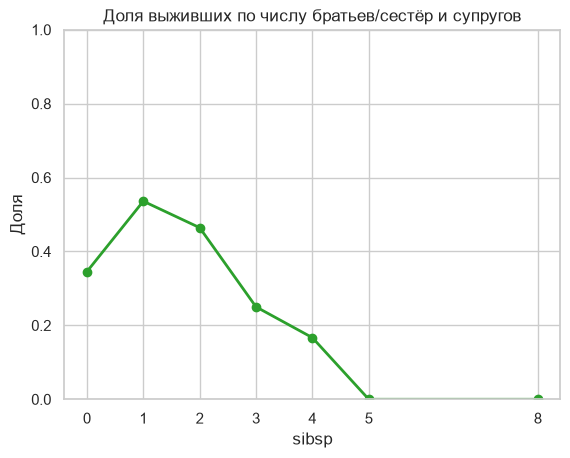

In [32]:
# matplotlib: агрегация явно видна в коде.
by_sibsp = data.groupby('sibsp')['survived'].agg(['mean', 'count']).sort_index()
print(by_sibsp.rename(columns={'mean': 'доля выживших', 'count': 'пассажиров'}))


plt.plot(by_sibsp.index, by_sibsp['mean'], marker='o', linewidth=2, color='tab:green')


# оформление
plt.title('Доля выживших по числу братьев/сестёр и супругов')
plt.xlabel('sibsp'); plt.ylabel('Доля'); plt.ylim(0, 1)
plt.xticks(by_sibsp.index)
plt.show()

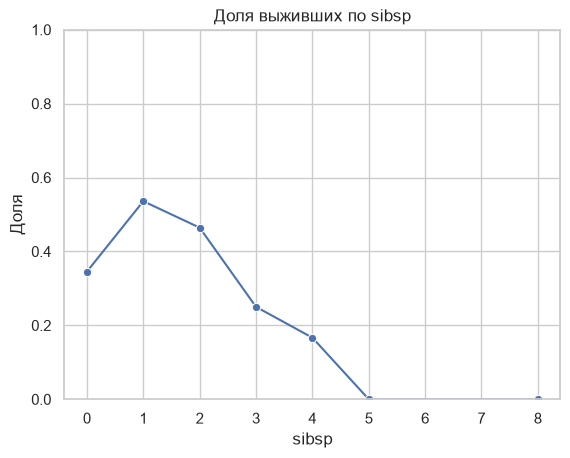

In [33]:
# seaborn сам агрегирует y для одинаковых x; estimator='mean' — значение по умолчанию.
sns.lineplot(data=data, x='sibsp', y='survived', estimator='mean', errorbar=None, marker='o')

# оформление
plt.title('Доля выживших по sibsp')
plt.xlabel('sibsp'); plt.ylabel('Доля'); plt.ylim(0, 1)
plt.show()

### Lineplot: ключи и ловушки

| Ключ | Зачем |
|---|---|
| marker='o' | показывает, где есть настоящие агрегированные точки |
| linewidth=2 | делает линию читаемой |
| estimator='mean' | seaborn считает среднее Y для одинакового X |
| errorbar=None | убрать интервалы вокруг среднего, если они не нужны |
| hue='sex' | отдельная линия на группу |
| sort=False | почти никогда не нужен; по умолчанию seaborn сортирует X |
| plt.ylim(0, 1) | обязательная шкала для долей/вероятностей |

Всегда смотрите на count рядом с агрегированным средним: точка 100% среди одного пассажира ненадёжна.

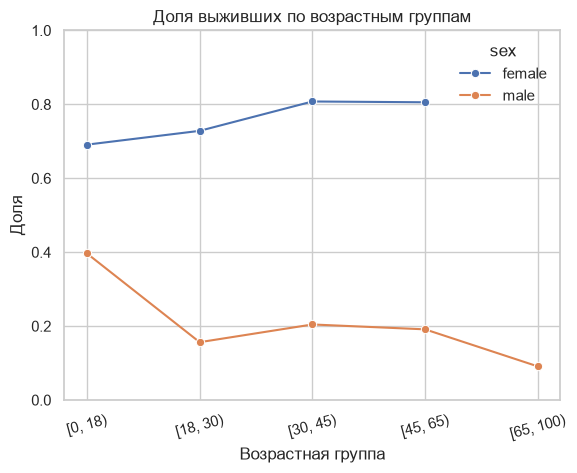

In [34]:
# Две линии: сначала считаем группы явно, затем рисуем.
age_groups = data.dropna(subset=['age']).copy()
age_groups['age_band'] = pd.cut(age_groups['age'], [0, 18, 30, 45, 65, 100], right=False)
rates = age_groups.groupby(['age_band', 'sex'], observed=True)['survived'].mean().reset_index()
# seaborn ждёт числовую или строковую ось X; интервалы превращаем в читаемые подписи.
rates['age_band_label'] = rates['age_band'].astype(str)


sns.lineplot(data=rates, x='age_band_label', y='survived', hue='sex', marker='o', errorbar=None)


# оформление
plt.title('Доля выживших по возрастным группам')
plt.xlabel('Возрастная группа'); plt.ylabel('Доля'); plt.ylim(0, 1)
plt.xticks(rotation=15); plt.show()

# 4. Pairplot: быстрый обзор числовых признаков

Pairplot строит матрицу scatter-графиков для всех пар числовых признаков и распределения на диагонали. Это отличный первый взгляд на маленькую таблицу: сразу заметны корреляции, кластеры, разделение классов и выбросы.

Но pairplot растёт квадратично: 8 признаков дадут 64 панели. Для олимпиады передавайте только 2–4 нужных числовых столбца и при большом наборе берите sample.

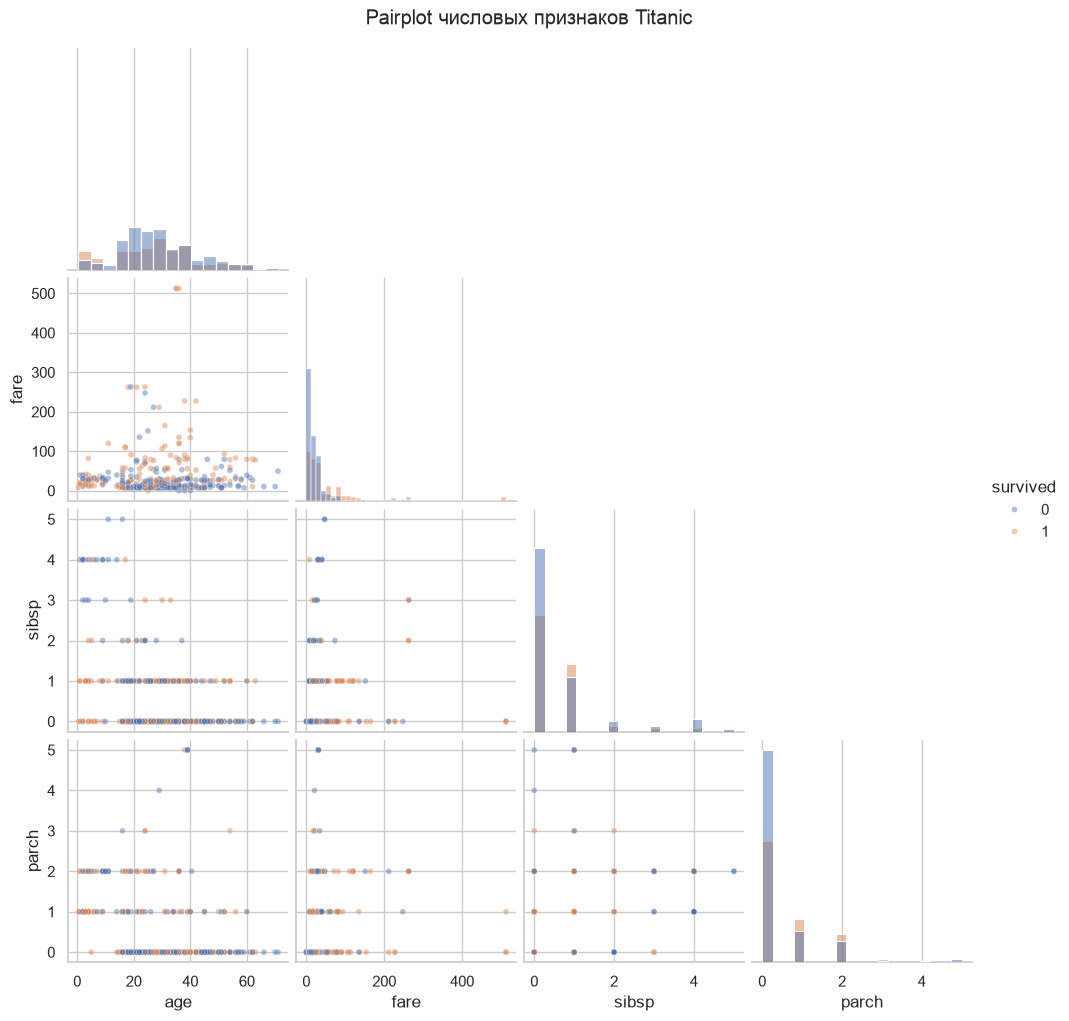

In [35]:
# seaborn: самый удобный настоящий pairplot.
pair_data = data[['age', 'fare', 'sibsp', 'parch', 'survived']].dropna().sample(n=400, random_state=42)
g = sns.pairplot(pair_data, vars=['age', 'fare', 'sibsp', 'parch'], hue='survived', corner=True, diag_kind='hist', plot_kws={'alpha': .45, 's': 18})
g.fig.suptitle('Pairplot числовых признаков Titanic', y=1.02)
plt.show()

### Pairplot: важные ключи

| Ключ | Зачем |
|---|---|
| vars=['age', 'fare'] | явно выбрать числовые столбцы |
| hue='survived' | раскрасить точки по классу |
| corner=True | оставить только нижний треугольник; вдвое меньше повторов |
| diag_kind='hist' | гистограмма на диагонали; возможен kde |
| plot_kws={'alpha': .4} | ключи для scatter внутри матрицы |
| sample(n=500, random_state=42) | ускорить график на большой таблице |

У matplotlib нет встроенного pairplot. Ближайшая быстрая замена — pandas.scatter_matrix, которая рисуется средствами matplotlib.

# 5. Олимпиадная шпаргалка: готовые рецепты

### Увидеть данные быстро

    df[['age', 'fare', 'sibsp']].describe()
    df.isna().sum()
    df.groupby('class')['survived'].agg(['mean', 'count'])

### Scatter с категорией

    sns.scatterplot(data=df, x='age', y='fare', hue='survived', alpha=.5)

### Hist по группам

    sns.histplot(data=df, x='age', hue='pclass', bins=20, multiple='dodge', alpha=.4)

### Линия после группировки

    result = df.groupby('sibsp')['survived'].mean().sort_index()
    plt.plot(result.index, result.values, marker='o')

### Pairplot без тормозов

    small = df[['age', 'fare', 'sibsp', 'survived']].dropna().sample(500, random_state=42)
    sns.pairplot(small, hue='survived', corner=True)

### Быстрая диагностика ошибки

- Нет графика: проверьте, что вызвали plt.show().
- Много NaN: передайте dropna(subset=['нужные столбцы']).
- Линия идёт странно: сначала sort_values/sort_index или groupby.
- Доля выглядит больше 1: перепутаны count и mean.
- Pairplot завис: оставьте только нужные vars и возьмите sample.